# Final report



In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from jaxopt import AndersonAcceleration
import pickle
import os
import optax
from scipy import stats
from scipy.optimize import curve_fit
import pandas as pd
import seaborn as sns
from tqdm import trange
from itertools import product
import openpyxl
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment




## 1. Naka–Rushton 

Fixing Hill exponents from Elisa

In [3]:
# Naka-Rushton function

def nr(x, n):
    """Naka-Rushton activation function"""
    x = jnp.maximum(x, 0.0)
    return jnp.power(x, n) / (jnp.power(x, n) + 1)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


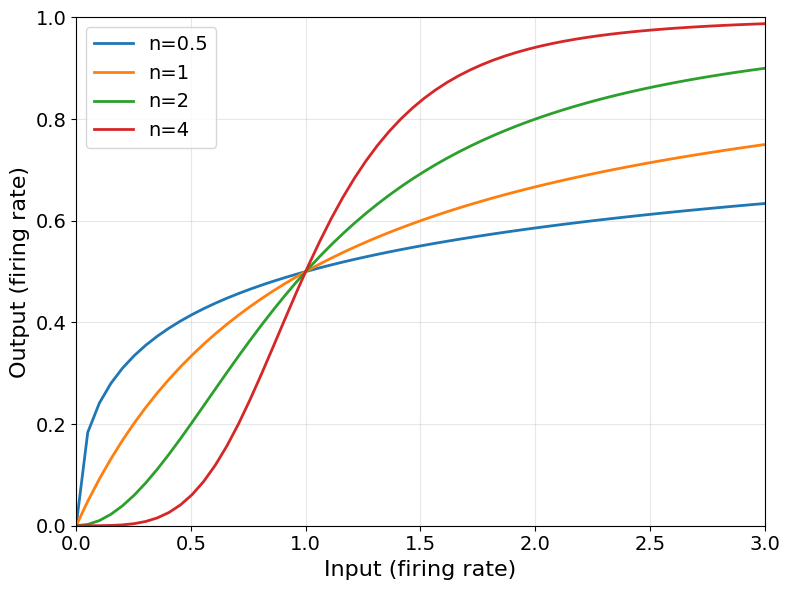

In [4]:
# Visualise the Naka-Rushton function
x_vals = jnp.linspace(0, 5, 100)
n_values = [0.5, 1, 2, 4]

plt.figure(figsize=(8, 6))
for n in n_values:
    y_vals = nr(x_vals, n=n)
    plt.plot(x_vals, y_vals, label=f'n={n}', linewidth=2)

plt.xlabel('Input (firing rate)', fontsize=16)
plt.ylabel('Output (firing rate)', fontsize=16)
plt.grid(True, alpha=0.3)
plt.xlim(0, 3)
plt.ylim(0, 1)
plt.tick_params(axis='both', direction='out', labelsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.savefig(f'Figures_final/naka_rushton_og.eps')
plt.show()

In [5]:
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

## 2. Symmetric weight



In [6]:

def unpack_theta(theta, m):
    w_osn_r = jnp.array([theta[0], theta[0]])
    w_osn_b = jnp.array([theta[1], theta[1]])
    w_osn_g = jnp.array([theta[2], theta[2]])
    w_osn_y = jnp.array([theta[3], theta[3]])
    w_b_r = jnp.array([theta[4], theta[4]])
    w_b_g = jnp.array([theta[5], theta[5]])
    w_b_y = jnp.array([theta[6], theta[6]])
    w_r_y = jnp.array([theta[7], theta[7]])
    w_r_g = jnp.array([theta[8], theta[8]])
    alpha = jnp.array([theta[9], theta[9]])
    # Build 2x2 matrices so all elements are same type (avoids JAX shape error)
    zero = jnp.asarray(0.0)
    wr = jnp.asarray(theta[10])
    wy = jnp.asarray(theta[11])
    W_g_r = jnp.stack([jnp.stack([zero, wr]), jnp.stack([wr, zero])])
    W_g_y = jnp.stack([jnp.stack([zero, wy]), jnp.stack([wy, zero])])
    return w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y


# Fixed-point function for green neurons with different n values
def mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g):
    """Fixed point equation for green neurons with different n values"""
    b_input = w_osn_b * alpha * x
    b_out = nr(b_input, n=n_b)

    r_input = w_osn_r * alpha * x - w_b_r * b_out - W_g_r @ g
    r_out = nr(r_input, n=n_r)

    g_input = w_osn_g * alpha * x - w_b_g * b_out + w_r_g * r_out
    g_new = nr(g_input, n=n_g)

    return g_new

# Solve fixed point via Anderson Acceleration with different n values
def solve_fixed_point(theta, x, m, n_r, n_b, n_g):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)
    g0 = jnp.zeros(m)

    # Create a function with the n values baked in that matches AndersonAcceleration signature
    def fixed_point_with_n(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha):
        return mitral_fixed_point(g, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha, n_r, n_b, n_g)

    aa = AndersonAcceleration(fixed_point_with_n, history_size=5, tol=1e-10, maxiter=50)
    solution = aa.run(g0, x, w_osn_r, w_osn_b, w_osn_g, w_b_r, w_b_g, W_g_r, w_r_g, alpha)
    return solution.params

# Compute mitral output with different n values
def mitral_output(theta, x, m, n_r, n_b, n_g, n_y):
    w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g, alpha, W_g_r, W_g_y = unpack_theta(theta, m)

    g = solve_fixed_point(theta, x, m, n_r, n_b, n_g)
    b = nr(w_osn_b * alpha * x, n=n_b)
    r = nr(w_osn_r * alpha * x - w_b_r * b - W_g_r @ g, n=n_r)
    y = nr(w_osn_y * alpha * x - w_b_y * b - W_g_y @ g + w_r_y * r, n=n_y)

    return r, g, b, y

## 3. Random initialisations and Adam optimisation to hit output targets

- draw many initial `theta`
- minimise a squared-error loss on target firing rates
- keep converged solutions

In [7]:
# set up optimisation problem
m = 2  # number of mitral neurons
n_var = 4  # r, g, b, y
n = n_var * m  # total state length
x = jnp.ones(m)  # input odour signal

# Naka-Rushton n values for each neuron type
n_r = 1.850
n_g = 1.868
n_b = 0.642
n_y = 1.562

# target firing rates (all neurons should fire around 0.5)
y_target = jnp.array([0.5, 0.5])  # mitral cell output
g_target = jnp.array([0.5, 0.5])  # green neurons
b_target = jnp.array([0.5, 0.5])  # blue neurons
r_target = jnp.array([0.5, 0.5])  # red neurons

# number of parameters in the model
# parameters: w_osn_r, w_osn_b, w_osn_g, w_osn_y, w_b_r, w_b_g, w_b_y, w_r_y, w_r_g,
#            alpha, W_g_r, W_g_y
no_params = 12  # total number of parameters

print(f"Setup:")
print(f"  - Number of mitral neurons (channels): {m}")
print(f"  - Number of parameters: {no_params}")
print(f"  - Target firing rates: {np.array(y_target)}")
print(f"  - Input signal: {np.array(x)}")
print(f"  - N values: n_r={n_r}, n_b={n_b}, n_g={n_g}, n_y={n_y}")

Setup:
  - Number of mitral neurons (channels): 2
  - Number of parameters: 12
  - Target firing rates: [0.5 0.5]
  - Input signal: [1. 1.]
  - N values: n_r=1.85, n_b=0.642, n_g=1.868, n_y=1.562


## 4. Load params, test stability 



In [8]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_626_samples_n_different.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt shape: (626, 12)
Number of samples: 626
Number of parameters per sample: 12


All stable, therefore can just use theta_opt

## 5. Hessian 


# Compute Hessian

Processing 626 samples...
  Sample 1/626...


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


  Sample 101/626...
  Sample 201/626...
  Sample 301/626...
  Sample 401/626...
  Sample 501/626...
  Sample 601/626...
Completed processing 626 samples


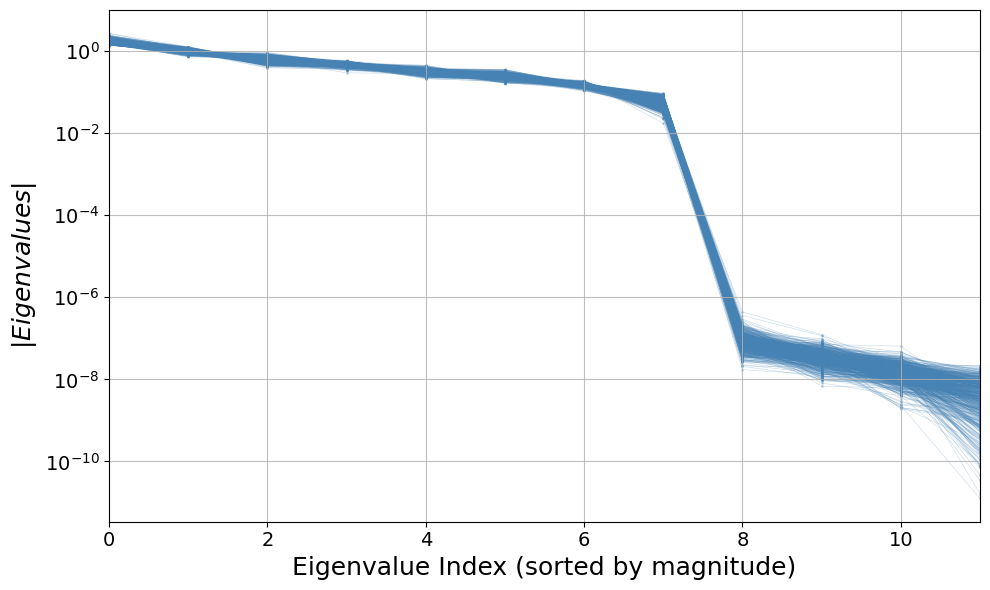

In [9]:
@jax.jit
def y_output_sum(theta):
    """Compute output y as a function of parameters"""
    r, g, b, y = mitral_output(theta, x, m, n_r, n_b, n_g, n_y)
    return jnp.sum(y)

grad = jax.jit(jax.grad(y_output_sum))
hessian = jax.jit(jax.jacrev(grad))

theta_samples = theta_opt
near_zero_threshold = 1e-5

print(f"Processing {theta_samples.shape[0]} samples...")
n_samples, n_params = theta_samples.shape[0], theta_samples.shape[1]
all_eigenvalues = np.zeros((n_samples, n_params))
all_eigenvectors = np.zeros((n_samples, n_params, n_params))

# Process all samples
for i in range(n_samples):
    if i % 100 == 0:
        print(f"  Sample {i+1}/{n_samples}...")

    theta_star = jnp.array(theta_samples[i, :])
    H = jnp.squeeze(hessian(theta_star))

    # Compute and sort eigenvalues in one step
    eigenvalues_H = np.array(jnp.linalg.eigh(H).eigenvalues)
    eigenvectors_H = np.array(jnp.linalg.eigh(H).eigenvectors)
    all_eigenvalues[i, :] = np.abs(eigenvalues_H[np.argsort(np.abs(eigenvalues_H))[::-1]])
    all_eigenvectors[i, :, :] = eigenvectors_H[:, np.argsort(np.abs(eigenvalues_H))[::-1]]

print(f"Completed processing {n_samples} samples")

# Visualise
fig, ax = plt.subplots(figsize=(10, 6))
n_params = all_eigenvalues.shape[1]

# Plot individual samples (light, transparent)
ax.semilogy(all_eigenvalues.T, 'o-', ms=1, lw=0.4, alpha=0.3, color='steelblue', zorder=1)

# Plot statistics
ax.set_xlabel('Eigenvalue Index (sorted by magnitude)', fontsize=18)
ax.set_ylabel('$|Eigenvalues|$', fontsize=18)
ax.set_xlim(0, n_params-1)
ax.tick_params(axis='both', labelsize=14, direction='out')
ax.grid(True, alpha=0.8)
plt.savefig('Figures_final/hessian_eigenvalues.eps')

plt.tight_layout()
plt.show()

In [10]:

threshold = 1e-5  # Threshold for near-zero eigenvalues

def get_subspace2_eigenvectors(sample_idx, all_eigenvalues, all_eigenvectors, threshold=1e-5):

    eigenvalues = all_eigenvalues[sample_idx, :]
    eigenvectors = all_eigenvectors[sample_idx, :, :]  # Shape: (n_params, n_params)

    # Find indices where eigenvalues < threshold
    near_zero_mask = eigenvalues < threshold
    n_near_zero = np.sum(near_zero_mask)

    # Extract corresponding eigenvectors (each column is an eigenvector)
    eigenvectors_subspace2 = eigenvectors[:, near_zero_mask].T  # Shape: (n_near_zero, n_params)

    return eigenvectors_subspace2

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


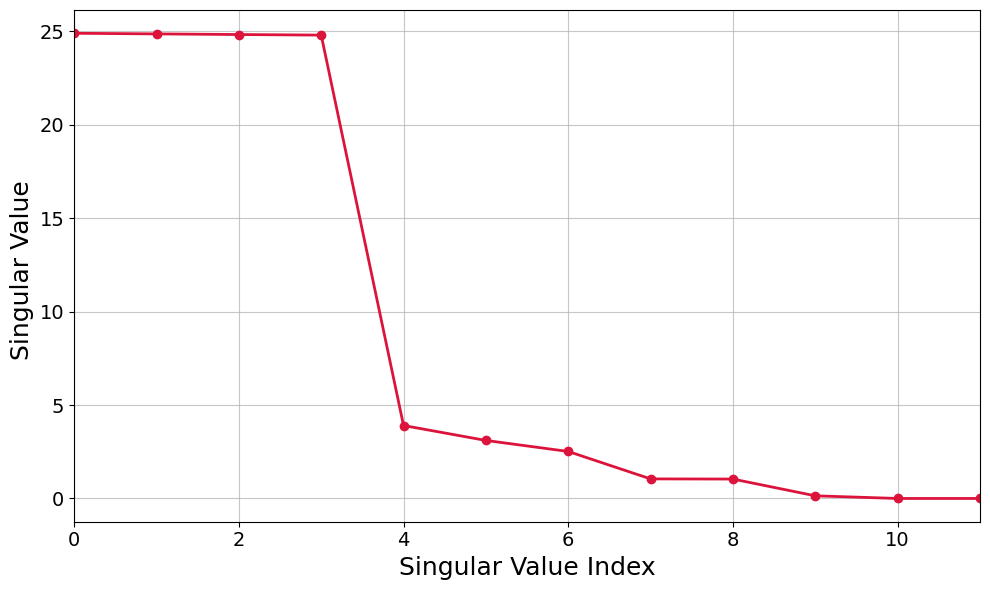

In [11]:

# Concatenate all near-zero eigenvectors from all samples
all_eigenvectors_subspace2 = []
for i in range(n_samples):
    vecs = get_subspace2_eigenvectors(i, all_eigenvalues, all_eigenvectors, threshold=threshold)
    all_eigenvectors_subspace2.append(vecs)
# Stack all (variable-sized, so use vstack)
eigenvectors_concat = np.vstack(all_eigenvectors_subspace2)  # Shape: (total_vectors, n_params)

# Perform SVD on concatenated eigenvectors
U, S, Vt = np.linalg.svd(eigenvectors_concat, full_matrices=False)

# Plot singular values vs index
plt.figure(figsize=(10, 6))
plt.plot(np.arange(0, len(S)), S, 'o-', color='crimson', lw=2, ms=6)
plt.xlabel('Singular Value Index', fontsize=18)
plt.ylabel('Singular Value ', fontsize=18)
plt.xlim(0, len(S)-1)
plt.grid(True, alpha=0.7)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.savefig('Figures_final/svd_singular_values.eps')
plt.show()

In [12]:
Vt[:4].shape # orthonormal rows
Vt[:4].T.shape # orthonormal columns

(12, 4)

## 6. Find sparse rotation


In [13]:
def sparse_rotation_vectorized(U, keys, learning_rate=0.01, n_iterations=10000):
    """Find sparse rotations for many random Q initialisations (JIT + vmap)."""
    k = U.shape[1]

    def loss(qtilde):
        q, _ = jnp.linalg.qr(qtilde)
        return jnp.mean(jnp.abs(U @ q))

    def optimize_single(key):
        key, subkey = jax.random.split(key)
        qtilde = jax.random.normal(subkey, (k, k))
        optimizer = optax.adam(learning_rate=learning_rate, eps=1e-4)
        opt_state = optimizer.init(qtilde)
        loss_value_and_grad = jax.value_and_grad(loss)

        def step(carry, _):
            qtilde, opt_state = carry
            loss_value, grads = loss_value_and_grad(qtilde)
            updates, opt_state = optimizer.update(grads, opt_state)
            qtilde = optax.apply_updates(qtilde, updates)
            return (qtilde, opt_state), loss_value

        (qtilde_final, _), loss_history = jax.lax.scan(
            step, (qtilde, opt_state), jnp.arange(n_iterations)
        )
        q_opt, _ = jnp.linalg.qr(qtilde_final)
        return U @ q_opt, loss_history[-1]

    return jax.jit(jax.vmap(optimize_single))(keys)


def sparse_rotation(U, key=0, learning_rate=0.01, n_iterations=10000, verbose=False):
    """Single-initialisation wrapper around sparse_rotation_vectorized."""
    key = jax.random.PRNGKey(key) if isinstance(key, int) else key
    U_sparse, loss = sparse_rotation_vectorized(
        U, jnp.array([key]),
        learning_rate=learning_rate,
        n_iterations=n_iterations,
    )
    if verbose:
        print(f"Final loss: {float(loss[0]):.6f}")
    return np.asarray(U_sparse[0]), float(loss[0])

In [14]:
U_2, _ = sparse_rotation(Vt[:4].T)

In [15]:
# Three different Q-tilde initialisations (PRNG keys 0, 1, 2)
init_keys = [0, 1, 2, 3, 4]
U_sparse_runs = []
for init_key in init_keys:
    print(f"\n--- Q-tilde init key={init_key} ---")
    U_sparse, _ = sparse_rotation(Vt[:4].T, key=init_key, verbose=True)
    U_sparse_runs.append(U_sparse)

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y', 'w_r_y', 'w_r_g',
    'alpha', 'W_g_r', 'W_g_y'
]

n_inits = len(U_sparse_runs)
n_components = U_sparse_runs[0].shape[1]

# Save per-panel plot data for the next cell
sparse_rotation_q_rows = []
for init_key, U_sparse in zip(init_keys, U_sparse_runs):
    M = np.array(U_sparse)
    sorting_ind = np.argsort(np.abs(M).sum(0))[::-1]
    sparse_rotation_q_rows.append({
        'init_key': init_key,
        'M_plot': M[:, sorting_ind],
        'sorting_ind': sorting_ind,
    })



--- Q-tilde init key=0 ---
Final loss: 0.142934

--- Q-tilde init key=1 ---
Final loss: 0.150743

--- Q-tilde init key=2 ---
Final loss: 0.142881

--- Q-tilde init key=3 ---
Final loss: 0.142941

--- Q-tilde init key=4 ---
Final loss: 0.150789


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


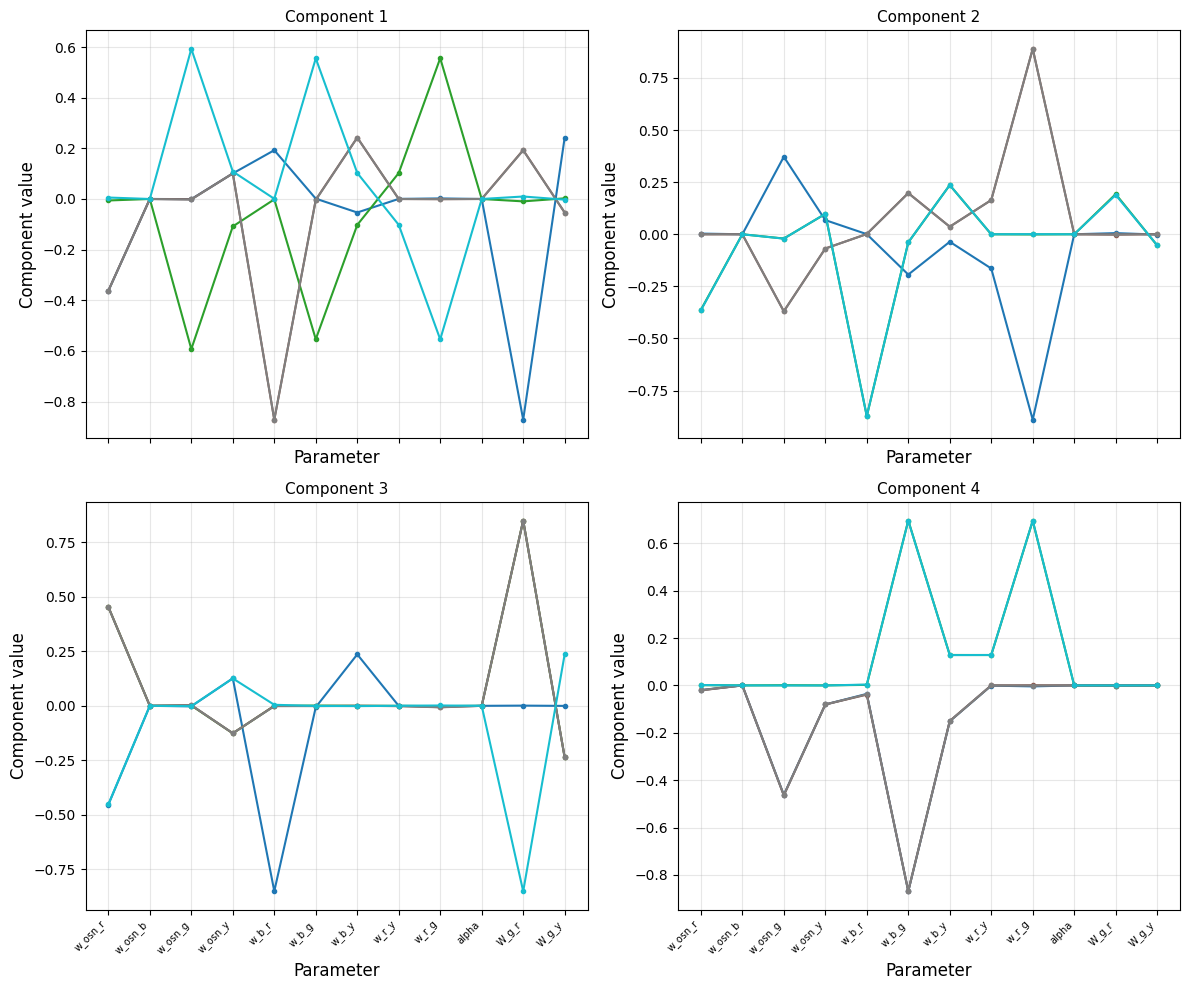

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=False)
axes = axes.flatten()
init_colors = plt.cm.tab10(np.linspace(0, 1, n_inits))

for col in range(n_components):
    ax = axes[col]
    for color, row_data in zip(init_colors, sparse_rotation_q_rows):
        init_key = row_data['init_key']
        M_plot = row_data['M_plot']
        ax.plot(
            M_plot[:, col], '.-',
            color=color,
            label=f'init key={init_key}',
        )
    ax.set_xticks(range(len(param_labels)))
    ax.set_xticklabels(param_labels, rotation=45, ha='right', fontsize=7)
    ax.set_title(f'Component {col + 1}', fontsize=11)
    ax.set_ylabel('Component value', fontsize=12)
    ax.grid(True, alpha=0.3)
    #ax.legend(fontsize=8, loc='best')

for j in range(n_components, len(axes)):
    axes[j].set_visible(False)

for ax in axes[:n_components]:
    ax.set_xlabel('Parameter', fontsize=12)

plt.tight_layout()
plt.savefig('Figures_final/sparse_rotation_several_Q.eps')
plt.show()

## 7. Many Q tilde initialisations




In [17]:
def sparse_rotation(
    U, key, use_scheduler=True, scheduler_type='plateau', verbose=True
):

    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))


    # Initialise Adam optimizer with learning rate scheduler
    key = jax.random.PRNGKey(key)
    key, subkey = jax.random.split(key)
    k = U.shape[1]  # Number of columns
    qtilde = jax.random.normal(subkey, (k, k))  # Fixed: should be (k, k) not (r, k)
    
    # Set up learning rate schedule
    if use_scheduler:
        if scheduler_type == 'cosine':
            # Cosine decay: more gradual reduction, keeps LR high for longer
            schedule = optax.cosine_decay_schedule(
                init_value=0.01,
                decay_steps=10000,  # Full decay over all iterations
                alpha=0.1  # Final LR will be 0.01 * 0.1 = 0.001
            )
            optimizer = optax.chain(
                optax.scale_by_adam(eps=1e-4),
                optax.scale_by_schedule(schedule)
            )
        elif scheduler_type == 'step':
            # Step decay: reduce LR at specific milestones (much later)
            schedule = optax.piecewise_constant_schedule(
                init_value=0.01,
                boundaries_and_scales={5000: 0.5, 8000: 0.5}  # Reduce by 0.5x at 5000 and 8000
            )
            optimizer = optax.chain(
                optax.scale_by_adam(eps=1e-4),
                optax.scale_by_schedule(schedule)
            )
        else:  # 'plateau' - reduce LR when loss plateaus
            # Start with fixed LR, will adjust manually
            schedule = None
            optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
    else:
        schedule = None
        optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
    
    opt_state = optimizer.init(qtilde)

    # Create value_and_grad function
    loss_value_and_grad = jax.value_and_grad(loss)

    # Track loss history
    loss_history = []
    n_iterations = 10000
    
    # For plateau scheduler: track best loss and patience
    if use_scheduler and scheduler_type == 'plateau':
        best_loss = float('inf')
        patience = 2000  # Wait 2000 iterations before reducing LR
        patience_counter = 0
        current_lr = 0.01
        lr_reduction_factor = 0.5
        min_lr = 0.0001

    # Optimization loop
    for iteration in range(n_iterations):
        loss_value, grads = loss_value_and_grad(qtilde)
        
        # For plateau scheduler: check if we should reduce LR
        if use_scheduler and scheduler_type == 'plateau':
            if loss_value < best_loss:
                best_loss = float(loss_value)
                patience_counter = 0
            else:
                patience_counter += 1
                
            if patience_counter >= patience and current_lr > min_lr:
                current_lr = max(current_lr * lr_reduction_factor, min_lr)
                # Reinitialize optimizer with new LR
                optimizer = optax.adam(learning_rate=current_lr, eps=1e-4)
                opt_state = optimizer.init(qtilde)
                patience_counter = 0
                if verbose:
                    print(f"  Reduced LR to {current_lr:.6f} at iteration {iteration}")
        
        updates, opt_state = optimizer.update(grads, opt_state)
        qtilde = optax.apply_updates(qtilde, updates)
        
        # Track loss
        loss_history.append(float(loss_value))

        if iteration % 10000 == 0 and verbose:
            if use_scheduler and scheduler_type == 'plateau':
                lr_display = current_lr
            elif use_scheduler and schedule is not None:
                lr_display = schedule(iteration)
            else:
                lr_display = 0.01
            print(f"Iteration {iteration}, Loss: {float(loss_value):.8f}, LR: {lr_display:.6f}")

    # Get optimized q
    q_opt,_ = jnp.linalg.qr(qtilde)

    U_sparse = U @ q_opt
    return U_sparse, loss_value, loss_history

#U_sparse = sparse_rotation(Vt[:4].T)

In [18]:
# Vectorized version of sparse_rotation for parallelization
def sparse_rotation_vectorized(U, keys, use_scheduler=True, scheduler_type='plateau', n_iterations=10000):

    batch_size = keys.shape[0]
    k = U.shape[1]
    n = U.shape[0]
    
    def loss(qtilde):
        """Loss function: mean of absolute values of rotated u"""
        q, _ = jnp.linalg.qr(qtilde)
        u_rotated = U @ q
        return jnp.mean(jnp.abs(u_rotated))
    
    def optimize_single(key):
        """Optimize for a single initialization"""
        key, subkey = jax.random.split(key)
        qtilde = jax.random.normal(subkey, (k, k))
        
        # Set up optimizer
        if use_scheduler:
            if scheduler_type == 'cosine':
                schedule = optax.cosine_decay_schedule(
                    init_value=0.01,
                    decay_steps=n_iterations,
                    alpha=0.1
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            elif scheduler_type == 'step':
                schedule = optax.piecewise_constant_schedule(
                    init_value=0.01,
                    boundaries_and_scales={5000: 0.5, 8000: 0.5}
                )
                optimizer = optax.chain(
                    optax.scale_by_adam(eps=1e-4),
                    optax.scale_by_schedule(schedule)
                )
            else:  # 'plateau' or default
                # For plateau, use fixed LR of 0.01
                # The original plateau scheduler keeps LR at 0.01 for most iterations
                # (reduces only when loss plateaus, typically after 3000+ iterations)
                # Using fixed 0.01 should give similar results since most optimization
                # happens at this LR anyway
                optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        else:
            optimizer = optax.adam(learning_rate=0.01, eps=1e-4)
        
        opt_state = optimizer.init(qtilde)
        loss_value_and_grad = jax.value_and_grad(loss)
        
        # Optimization loop - use scan for efficiency
        def step(carry, i):
            qtilde, opt_state = carry
            loss_value, grads = loss_value_and_grad(qtilde)
            updates, opt_state = optimizer.update(grads, opt_state)
            qtilde = optax.apply_updates(qtilde, updates)
            return (qtilde, opt_state), loss_value
        
        (qtilde_final, _), loss_history = jax.lax.scan(
            step, (qtilde, opt_state), jnp.arange(n_iterations)
        )
        
        # Get final Q
        q_opt, _ = jnp.linalg.qr(qtilde_final)
        U_sparse = U @ q_opt
        
        return U_sparse, loss_history[-1]
    
    # Vectorize over keys using vmap and JIT compile for speed
    optimize_batch = jax.jit(jax.vmap(optimize_single))
    
    # Process all keys in parallel (JIT compilation happens on first call)
    U_sparse_batch, loss_values = optimize_batch(keys)
    
    return U_sparse_batch, loss_values

In [19]:
# PARALLELIZED VERSION - Use this instead
n_key = 1000
batch_size = 100  # Process in batches to manage memory

n, k = Vt[:4].T.shape

# Configuration
config = {'use_scheduler': True, 'scheduler_type': 'plateau', 'label': 'Plateau Scheduler'}

# Generate all random keys upfront
print(f"Generating {n_key} random keys...")
keys = jax.random.split(jax.random.PRNGKey(0), n_key)

# Process in batches for memory efficiency
print(f"Processing {n_key} initializations in batches of {batch_size}...")
U_sparse_all = []
loss_values_all = []

for batch_start in trange(0, n_key, batch_size):
    batch_end = min(batch_start + batch_size, n_key)
    batch_keys = keys[batch_start:batch_end]
    
    # Process batch in parallel using JAX vmap
    U_sparse_batch, loss_batch = sparse_rotation_vectorized(
        Vt[:4].T,
        batch_keys,
        use_scheduler=config['use_scheduler'],
        scheduler_type=config['scheduler_type'] if config['use_scheduler'] else None,
        n_iterations=10000
    )
    
    U_sparse_all.append(np.array(U_sparse_batch))
    loss_values_all.append(np.array(loss_batch))

# Concatenate results
U_sparse_coll = np.concatenate(U_sparse_all, axis=0)
loss_value_coll = np.concatenate(loss_values_all, axis=0)

print(f"\nCompleted! Processed {n_key} initializations.")
print(f"Loss range: [{loss_value_coll.min():.6f}, {loss_value_coll.max():.6f}]")
print(f"Mean loss: {loss_value_coll.mean():.6f}")

np.savez_compressed('U_sparse_save.npz', U_sparse_coll=U_sparse_coll, loss_value_coll=loss_value_coll)

Generating 1000 random keys...
Processing 1000 initializations in batches of 100...


100%|██████████| 10/10 [00:14<00:00,  1.42s/it]


Completed! Processed 1000 initializations.
Loss range: [0.142865, 0.178115]
Mean loss: 0.145669


In [20]:
U_sparse_save = np.load('U_sparse_save.npz')['U_sparse_coll']
loss_value_coll = np.load('U_sparse_save.npz')['loss_value_coll']
U_sparse_save.shape
#loss_value_coll.shape

(1000, 12, 4)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


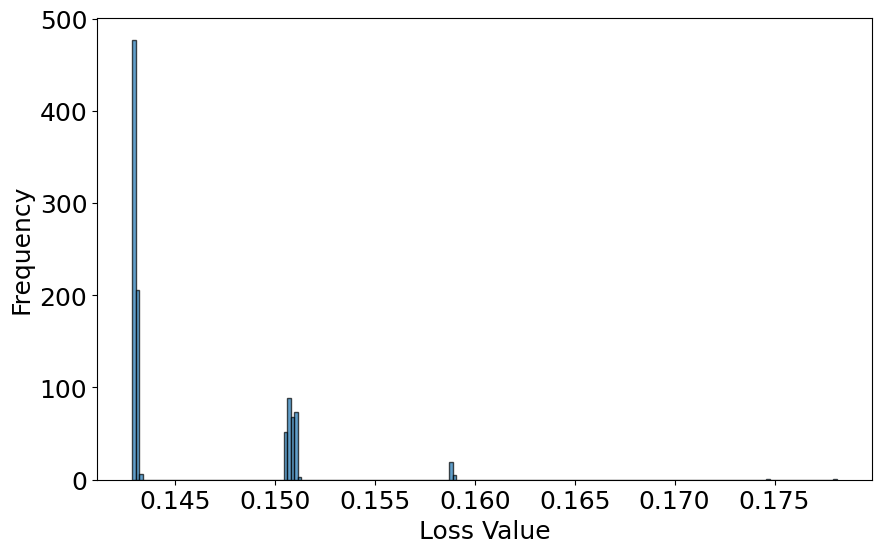

In [21]:
# plot histogram of loss values

plt.figure(figsize=(10,6))
plt.hist(loss_value_coll, bins=200, alpha=0.7, edgecolor='black')
plt.xlabel('Loss Value', fontsize=18)
plt.ylabel('Frequency', fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.savefig('Figures_final/sparse_loss_histogram.eps')
plt.show()


In [22]:
# Isolate lowest-loss cluster and check subspace matching
# Split all 1000 solutions into 3 broad clusters

kmeans3 = KMeans(n_clusters=3, random_state=0, n_init=10)
labels3 = kmeans3.fit_predict(loss_value_coll.reshape(-1, 1))
centroids3 = kmeans3.cluster_centers_.flatten()
best_cluster_id = np.argmin(centroids3)

best_mask_broad = labels3 == best_cluster_id
loss_broad = loss_value_coll[best_mask_broad]

print(f"3-cluster centroids (sorted): {np.sort(centroids3)}")
print(f"Broad lowest cluster: {best_mask_broad.sum()} solutions, "
      f"loss ∈ [{loss_broad.min():.6f}, {loss_broad.max():.6f}]")


3-cluster centroids (sorted): [0.14298965 0.1508187  0.1602259 ]
Broad lowest cluster: 689 solutions, loss ∈ [0.142865, 0.143242]


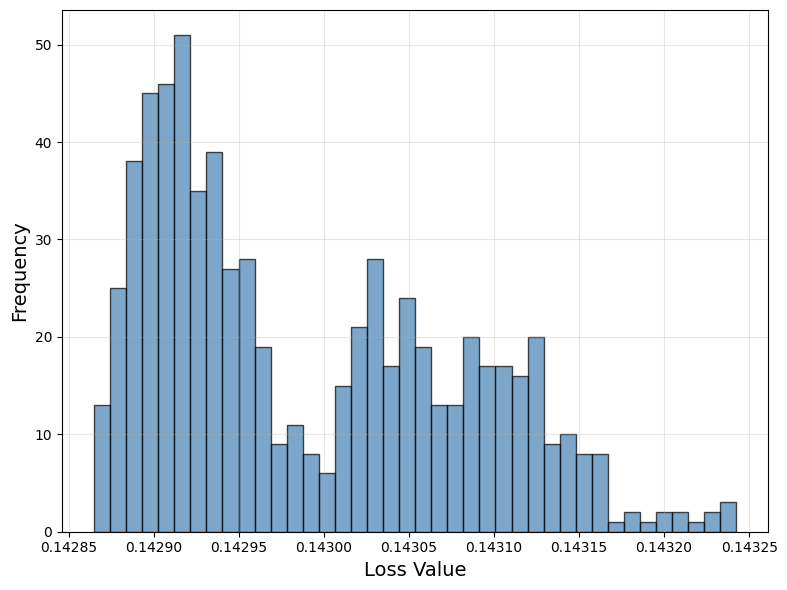

In [23]:
# Zoom into the lowest cluster (2 sub-peaks)
fig, ax = plt.subplots(figsize=(8, 6))

# Zoomed histogram of lowest broad cluster
ax.hist(loss_broad, bins=40, alpha=0.7, edgecolor='black', color='steelblue')
ax.set_xlabel('Loss Value', fontsize=14)
ax.set_ylabel('Frequency', fontsize=14)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.



Sub-cluster centroids: [0.14292139 0.14308135]
Lowest sub-peak: 395 solutions, loss ∈ [0.142865, 0.142999]


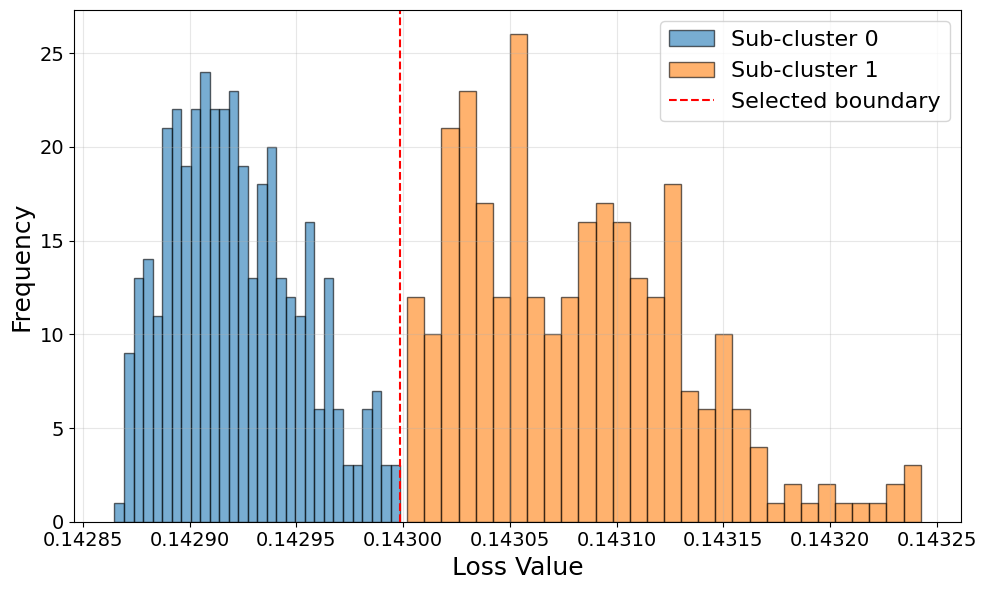

In [24]:
# Split the lowest broad cluster into 2 sub-clusters
kmeans2 = KMeans(n_clusters=2, random_state=0, n_init=10)
sub_labels = kmeans2.fit_predict(loss_broad.reshape(-1, 1))
sub_centroids = kmeans2.cluster_centers_.flatten()
best_sub_id = np.argmin(sub_centroids)

# Map back to original indices
broad_indices = np.where(best_mask_broad)[0]
sub_best_indices = broad_indices[sub_labels == best_sub_id]

U_best = U_sparse_save[sub_best_indices]          # shape: (n_best, 12, 4)
loss_best = loss_value_coll[sub_best_indices]

print(f"\nSub-cluster centroids: {np.sort(sub_centroids)}")
print(f"Lowest sub-peak: {U_best.shape[0]} solutions, "
      f"loss ∈ [{loss_best.min():.6f}, {loss_best.max():.6f}]")

# Show zoomed histogram with the 2 sub-clusters colour-coded
fig, ax = plt.subplots(figsize=(10, 6))
for sid in range(2):
    sub_mask = sub_labels == sid
    ax.hist(loss_broad[sub_mask], bins=30, alpha=0.6,
            label=f'Sub-cluster {sid}',
            edgecolor='black')
ax.axvline(loss_best.max(), color='red', ls='--', lw=1.5, label='Selected boundary')
ax.set_xlabel('Loss Value', fontsize=18)
ax.set_ylabel('Frequency', fontsize=18)
ax.legend(fontsize=16)
ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', which='major', labelsize=14)
plt.tight_layout()
plt.savefig('Figures_final/sparse_loss_histogram_2subpeaks.eps')
plt.show()

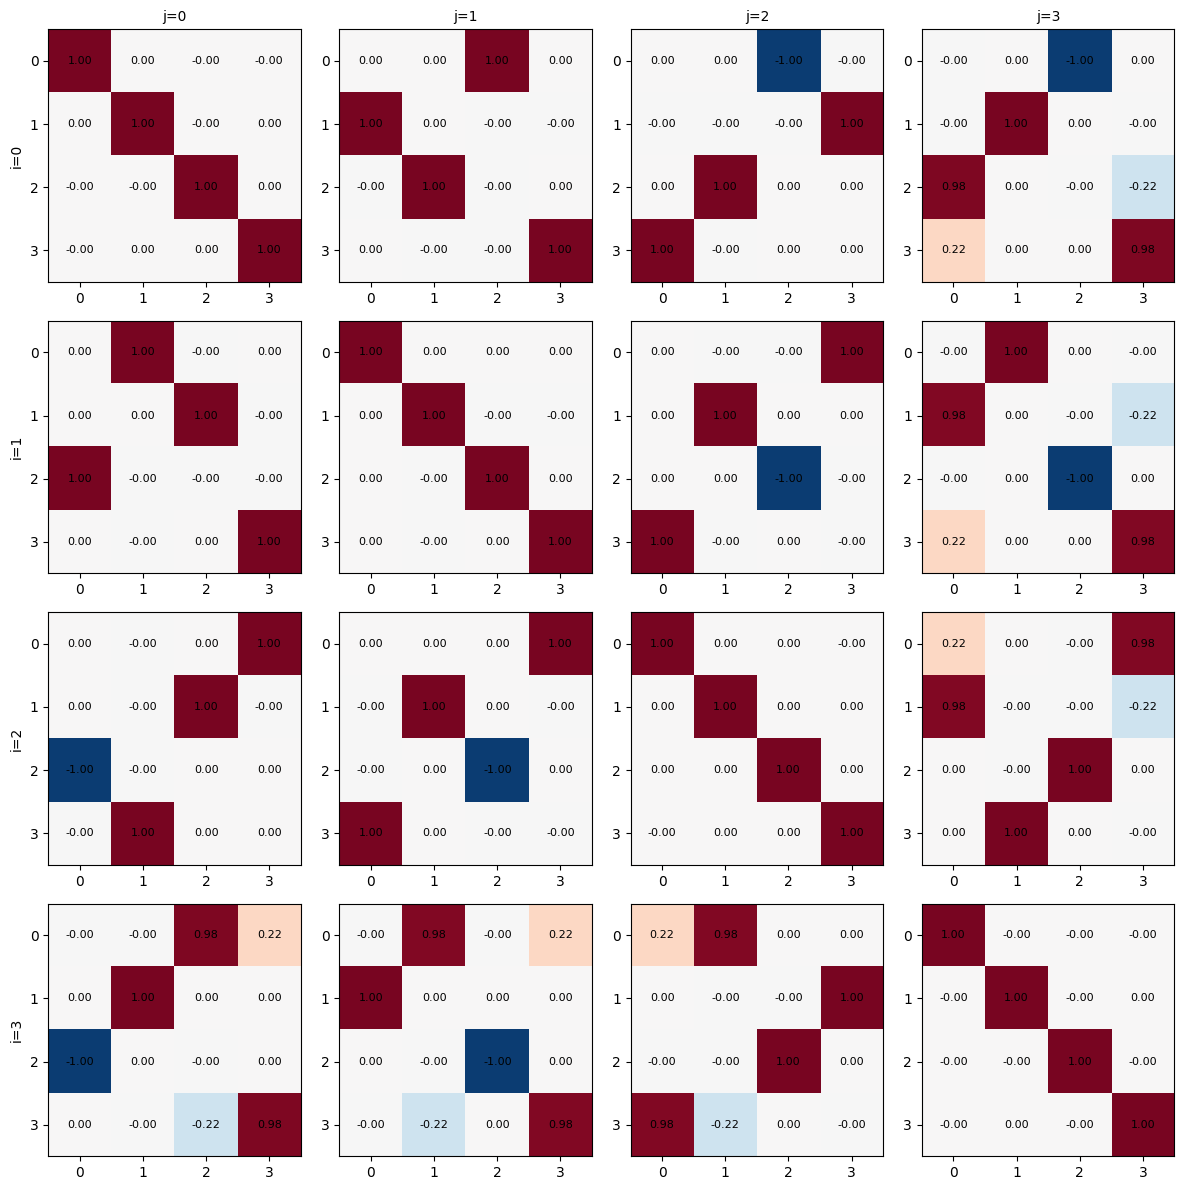

In [25]:
# Pairwise dot products  U_i^T @ U_j  for the lowest sub-peak
n_best = U_best.shape[0]
n_show = min(n_best, 4)

fig, axes_grid = plt.subplots(n_show, n_show, figsize=(3 * n_show, 3 * n_show))
for i in range(n_show):
    for j in range(n_show):
        P = U_best[i].T @ U_best[j]   # (4, 4)
        axes_grid[i, j].imshow(P, cmap='RdBu_r', vmin=-1.05, vmax=1.05)
        axes_grid[i, j].set_xticks(range(4))
        axes_grid[i, j].set_yticks(range(4))
        for ri in range(4):
            for ci in range(4):
                axes_grid[i, j].text(ci, ri, f'{P[ri, ci]:.2f}',
                                     ha='center', va='center', fontsize=8)
        if i == 0:
            axes_grid[i, j].set_title(f'j={j}', fontsize=10)
        if j == 0:
            axes_grid[i, j].set_ylabel(f'i={i}', fontsize=10)
plt.tight_layout()
plt.savefig('Figures_final/sparse_dot_products_4x4.eps')
plt.show()

In [26]:
# Quantitative signed-permutation check
max_off_perm = []
for i in range(n_best):
    for j in range(i + 1, n_best):
        P = U_best[i].T @ U_best[j]
        absP = np.abs(P)
        row_max = absP.max(axis=1)
        row_residual = absP.sum(axis=1) - row_max   # should be ~0
        max_off_perm.append(row_residual.max())

max_off_perm = np.array(max_off_perm)
print(f"\n── Signed permutation check ({n_best} solutions, "
      f"{len(max_off_perm)} pairs) ──")
print(f"Row residual (should be ~0):  mean={max_off_perm.mean():.4f},  "
      f"max={max_off_perm.max():.4f}")
#print(f"Pairs with residual < 0.10: {(max_off_perm < 0.10).mean():.1%}")
print(f"Pairs with residual < 0.05: {(max_off_perm < 0.05).mean():.1%}")
print(f"Pairs with residual < 0.01: {(max_off_perm < 0.01).mean():.1%}")


── Signed permutation check (395 solutions, 77815 pairs) ──
Row residual (should be ~0):  mean=0.1115,  max=0.2759
Pairs with residual < 0.05: 52.0%
Pairs with residual < 0.01: 43.3%


In [27]:
# Identify the two distinct sparse solutions and plot them

param_labels = [
    'w_osn_r', 'w_osn_b', 'w_osn_g', 'w_osn_y',
    'w_b_r', 'w_b_g', 'w_b_y',
    'w_r_y', 'w_r_g', 'alpha', 'W_g_r', 'W_g_y'
]

# Split U_best into 2 groups 
# Use solution 0 as reference: compute row residual of U_0^T @ U_j for all j
ref = U_best[0]  # (12, 4)
residuals = np.zeros(U_best.shape[0])
for j in range(U_best.shape[0]):
    P = ref.T @ U_best[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_A_mask = residuals < threshold
group_B_mask = ~group_A_mask

n_A, n_B = group_A_mask.sum(), group_B_mask.sum()
print(f"Group A (same as ref): {n_A} solutions")
print(f"Group B (different):   {n_B} solutions")

Group A (same as ref): 154 solutions
Group B (different):   241 solutions


In [28]:
# Sub-split Group B: use first Group B member as reference
U_B = U_best[group_B_mask]
ref_B = U_B[0]  # (12, 4)
residuals_B = np.zeros(U_B.shape[0])
for j in range(U_B.shape[0]):
    P = ref_B.T @ U_B[j]
    absP = np.abs(P)
    row_max = absP.max(axis=1)
    residuals_B[j] = (absP.sum(axis=1) - row_max).max()

threshold = 0.05
group_B1_mask = residuals_B < threshold
group_B2_mask = ~group_B1_mask

n_B1, n_B2 = group_B1_mask.sum(), group_B2_mask.sum()
print(f"Group B1 (same as ref_B): {n_B1} solutions")
print(f"Group B2 (different):     {n_B2} solutions")

Group B1 (same as ref_B): 240 solutions
Group B2 (different):     1 solutions



Representative A loss: 0.142871
Representative B loss: 0.142865

U_A^T @ U_B (should NOT be signed permutation):
[[-0.     0.001 -1.     0.002]
 [-0.001  0.001  0.002  1.   ]
 [ 0.222 -0.975 -0.001  0.002]
 [-0.975 -0.222  0.    -0.001]]


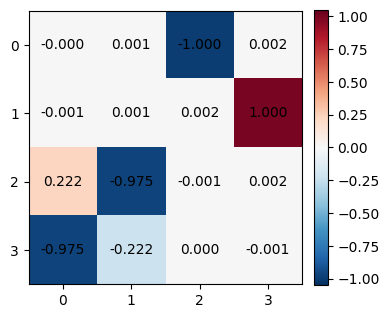

In [29]:
# Pick representative from each group (lowest loss within group) 
loss_A = loss_best[group_A_mask]
loss_B = loss_best[group_B_mask]
rep_A = U_best[group_A_mask][np.argmin(loss_A)]  # (12, 4)
rep_B = U_best[group_B_mask][np.argmin(loss_B)]  # (12, 4)

print(f"\nRepresentative A loss: {loss_A.min():.6f}")
print(f"Representative B loss: {loss_B.min():.6f}")

# Show the dot product between the two representatives
P_AB = rep_A.T @ rep_B
print(f"\nU_A^T @ U_B (should NOT be signed permutation):")
print(np.round(P_AB, 3))

fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(P_AB, cmap='RdBu_r', vmin=-1.05, vmax=1.05)
ax.set_xticks(range(4))
ax.set_yticks(range(4))
for ri in range(4):
    for ci in range(4):
        ax.text(ci, ri, f'{P_AB[ri, ci]:.3f}',
                ha='center', va='center', fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig('Figures_final/rep_AB_dot_product.eps')
plt.show()

In [30]:
# Sort columns by sparsity 
def sort_by_sparsity(M):
    sums = np.abs(M).sum(0)
    order = np.argsort(sums)[::-1]
    return M[:, order], order

rep_A_sorted, order_A = sort_by_sparsity(rep_A)
rep_B_sorted, order_B = sort_by_sparsity(rep_B)


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


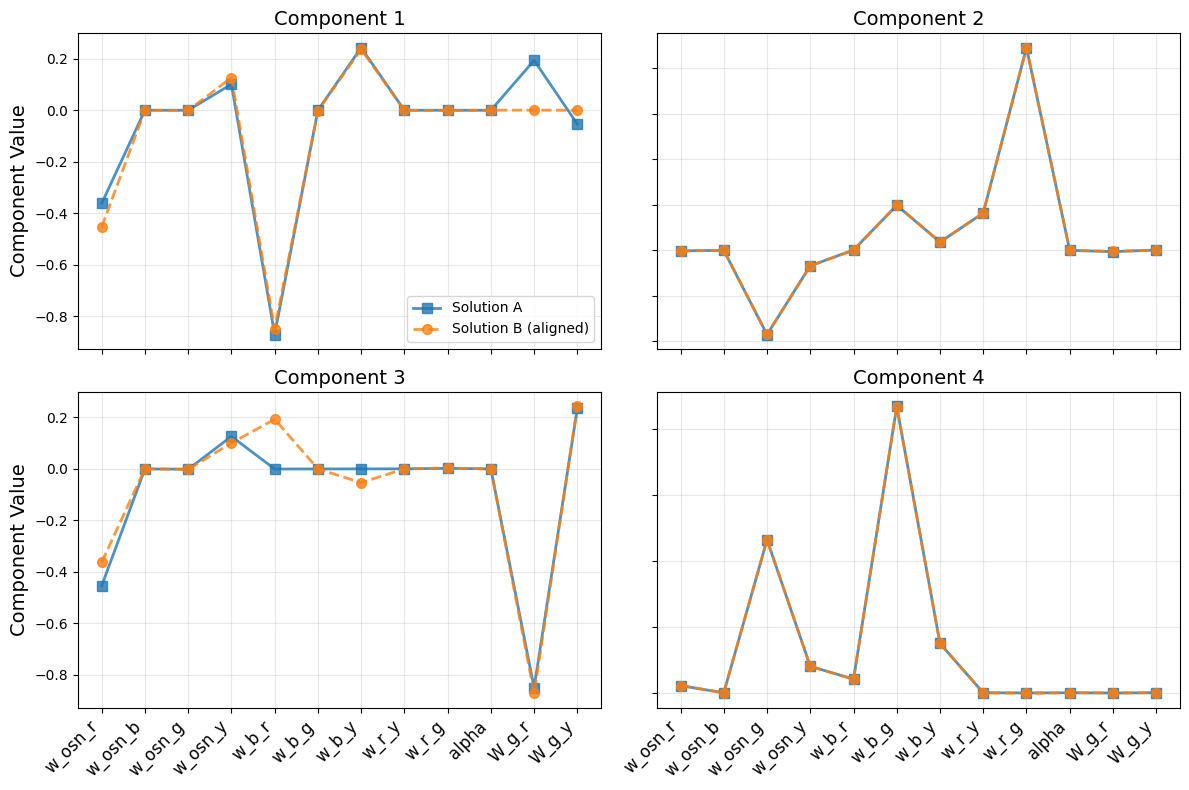


Sparsity pattern (entries with |value| > 0.1)

Solution A:
  Component 1: [('w_osn_r', '-0.362'), ('w_osn_y', '0.101'), ('w_b_r', '-0.871'), ('w_b_y', '0.243'), ('W_g_r', '0.194')]
  Component 2: [('w_osn_g', '-0.370'), ('w_b_g', '0.198'), ('w_r_y', '0.164'), ('w_r_g', '0.890')]
  Component 3: [('w_osn_r', '-0.454'), ('w_osn_y', '0.126'), ('W_g_r', '-0.850'), ('W_g_y', '0.236')]
  Component 4: [('w_osn_g', '0.464'), ('w_b_g', '0.868'), ('w_b_y', '0.150')]

Solution B (aligned):
  Component 1: [('w_osn_r', '-0.454'), ('w_osn_y', '0.127'), ('w_b_r', '-0.850'), ('w_b_y', '0.237')]
  Component 2: [('w_osn_g', '-0.369'), ('w_b_g', '0.199'), ('w_r_y', '0.164'), ('w_r_g', '0.890')]
  Component 3: [('w_osn_r', '-0.362'), ('w_osn_y', '0.101'), ('w_b_r', '0.193'), ('W_g_r', '-0.872'), ('W_g_y', '0.242')]
  Component 4: [('w_osn_g', '0.465'), ('w_b_g', '0.868'), ('w_b_y', '0.150')]


In [31]:

# Align B to A (optimal permutation + sign flips) 

# Compute cross-product between the sparsity-sorted versions
P = rep_A_sorted.T @ rep_B_sorted  # (4, 4)

# Hungarian algorithm: find permutation maximising sum of |P_ij|
# (linear_sum_assignment minimises cost, so negate)
row_ind, col_ind = linear_sum_assignment(-np.abs(P))

# Permute B's columns to match A's ordering
rep_B_aligned = rep_B_sorted[:, col_ind]

# Apply sign flips so each matched column has the same sign convention
signs = np.sign(np.array([P[r, c] for r, c in zip(row_ind, col_ind)]))
rep_B_aligned = rep_B_aligned * signs[None, :]


# Overlay – aligned comparison 
fig, axes2 = plt.subplots(2, 2, figsize=(12, 8))
axes2 = axes2.flatten()

for i in range(4):
    axes2[i].plot(rep_A_sorted[:, i], 's-', color='tab:blue', lw=2, ms=7,
                  label='Solution A', alpha=0.8)
    axes2[i].plot(rep_B_aligned[:, i], 'o--', color='tab:orange', lw=2, ms=7,
                  label='Solution B (aligned)', alpha=0.8)
    axes2[i].set_xticks(range(len(param_labels)))
    if i >= 2:
        axes2[i].set_xticklabels(param_labels, rotation=45, ha='right', fontsize=12)
    else:
        axes2[i].tick_params(labelbottom=False)
    if i % 2 == 0:
        axes2[i].set_ylabel('Component Value', fontsize=14)
    else:
        axes2[i].tick_params(labelleft=False)
    axes2[i].grid(True, alpha=0.3)
    axes2[i].set_title(f'Component {i+1}', fontsize=14)
    if i == 0:
        axes2[i].legend(fontsize=10)


plt.tight_layout()
plt.savefig('Figures_final/rep_AB_overlay.eps')
plt.show()

# Print sparsity patterns (both using aligned B) 
print("\nSparsity pattern (entries with |value| > 0.1)")
for label, M_sorted in [("Solution A", rep_A_sorted), ("Solution B (aligned)", rep_B_aligned)]:
    print(f"\n{label}:")
    for col in range(4):
        nonzero_params = [(param_labels[row], f"{M_sorted[row, col]:.3f}")
                          for row in range(12) if abs(M_sorted[row, col]) > 0.1]
        print(f"  Component {col+1}: {nonzero_params}")

In [32]:
# save the 4 12x4 matrices

rep_A_sorted.shape
rep_B_aligned.shape

np.savez('reps_aligned_A.npz', rep_A_sorted=rep_A_sorted)
np.savez('reps_aligned_B.npz', rep_B_aligned=rep_B_aligned)

## 8. Stepping along sparse directions in parameter space



In [33]:
# Load theta_opt from pickle file
theta_opt_file = 'Theta_opt/theta_opt_626_samples_n_different.pkl'
with open(theta_opt_file, 'rb') as f:
    theta_opt = pickle.load(f)

theta_opt = np.array(theta_opt)
initial_count = theta_opt.shape[0]  # Store initial count for summary
print(f"Loaded theta_opt with shape: {theta_opt.shape}")
print(f"Number of samples: {theta_opt.shape[0]}")
print(f"Number of parameters per sample: {theta_opt.shape[1]}")

Loaded theta_opt with shape: (626, 12)
Number of samples: 626
Number of parameters per sample: 12


In [34]:
'''
# load M
U_aligned = np.load('reps_aligned.npz')['reps_aligned']

U1= U_aligned[0]
U2= U_aligned[1]
U3= U_aligned[2]
U4= U_aligned[3]
'''

"\n# load M\nU_aligned = np.load('reps_aligned.npz')['reps_aligned']\n\nU1= U_aligned[0]\nU2= U_aligned[1]\nU3= U_aligned[2]\nU4= U_aligned[3]\n"

In [35]:

U_A_sorted = np.load('reps_aligned_A.npz')['rep_A_sorted']
U_B_aligned = np.load('reps_aligned_B.npz')['rep_B_aligned']

# Aligned reps may be (13, k) while mitral theta has 12 weights — slice rows to match theta_opt
n_theta = int(theta_opt.shape[1])
U1 = np.asarray(U_A_sorted, dtype=float)[:n_theta, :]
U2 = np.asarray(U_B_aligned, dtype=float)[:n_theta, :]

n_comp = U1.shape[1]
U3 = np.zeros((n_theta, n_comp))
U4 = np.zeros((n_theta, n_comp))



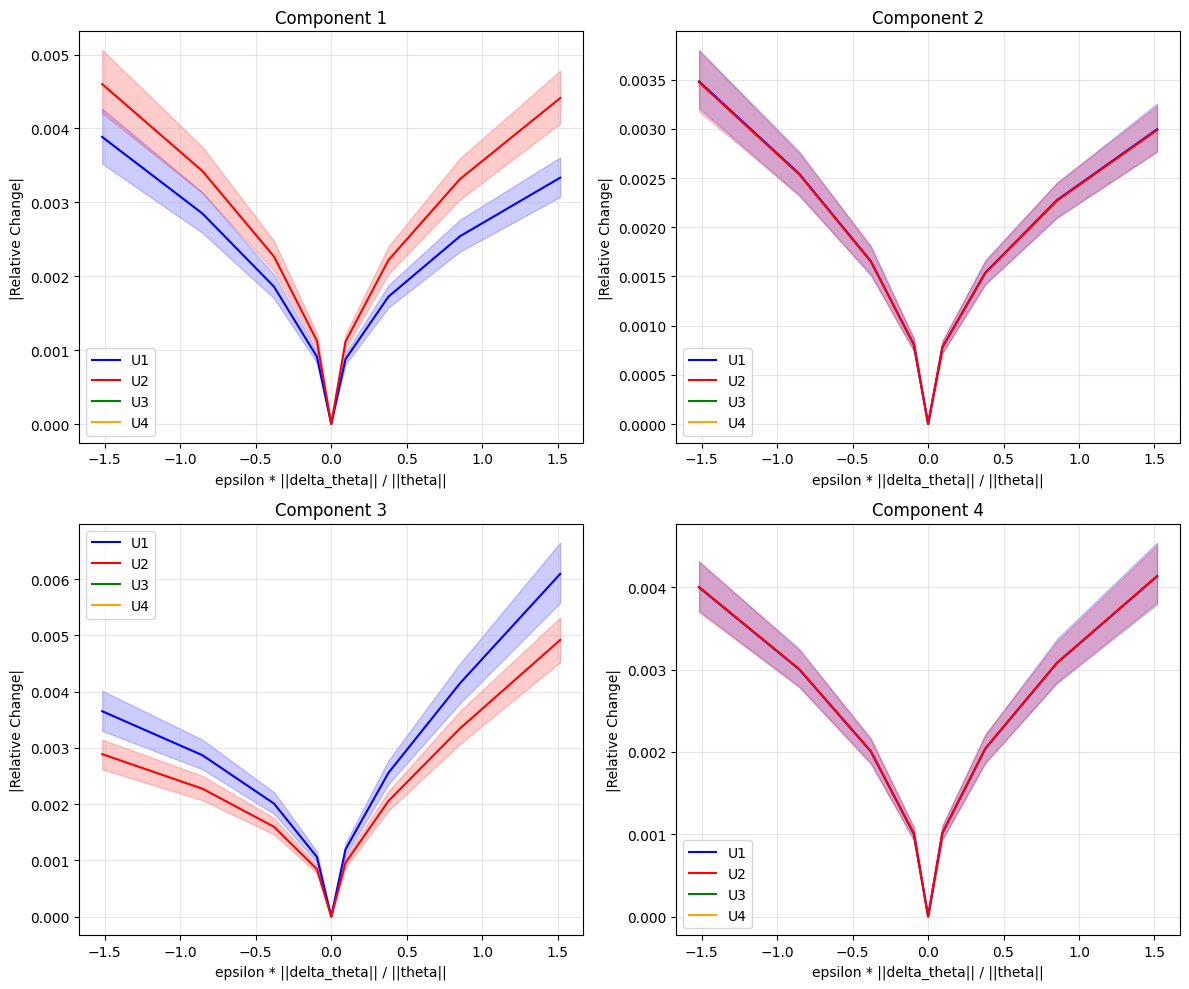

In [36]:
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 626

theta_opt_subset = jnp.array(theta_opt[:n_samples])

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

Us = [U1, U2, U3, U4]
u_labels = ['U1', 'U2', 'U3', 'U4']
u_colors = ['blue', 'red', 'green', 'orange']
n_components = Us[0].shape[1]

n_rows = int(np.ceil(n_components / 2))
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 5 * n_rows))
axes = np.atleast_1d(axes).flatten()
for j in range(n_components, len(axes)):
    axes[j].set_visible(False)

for M, u_label, color in zip(Us, u_labels, u_colors):
    for k in range(n_components):
        true_dir = jnp.array(M[:, k])
        true_dir = true_dir / jnp.linalg.norm(true_dir)

        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_subset + e[i] * true_dir
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)

        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * true_dir) / mean_norm_theta) for i in range(len(e))])
        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(np.abs(y0_baseline) > 1e-12,
                        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
                        y_array[:, :, 0] - y0_baseline)
        abs_rel0 = np.abs(rel0)
        theta_ratio_expanded = np.repeat(theta_ratio, n_samples)

        a = axes[k]
        sns.lineplot(x=theta_ratio_expanded, y=abs_rel0.ravel(), ax=a, color=color, label=u_label, errorbar=('ci', 95))

for k in range(n_components):
    axes[k].set_xlabel('epsilon * ||delta_theta|| / ||theta||')
    axes[k].set_ylabel('|Relative Change|')
    axes[k].set_title(f'Component {k+1}')
    axes[k].grid(True, alpha=0.3)
    axes[k].legend()

plt.tight_layout()
plt.show()

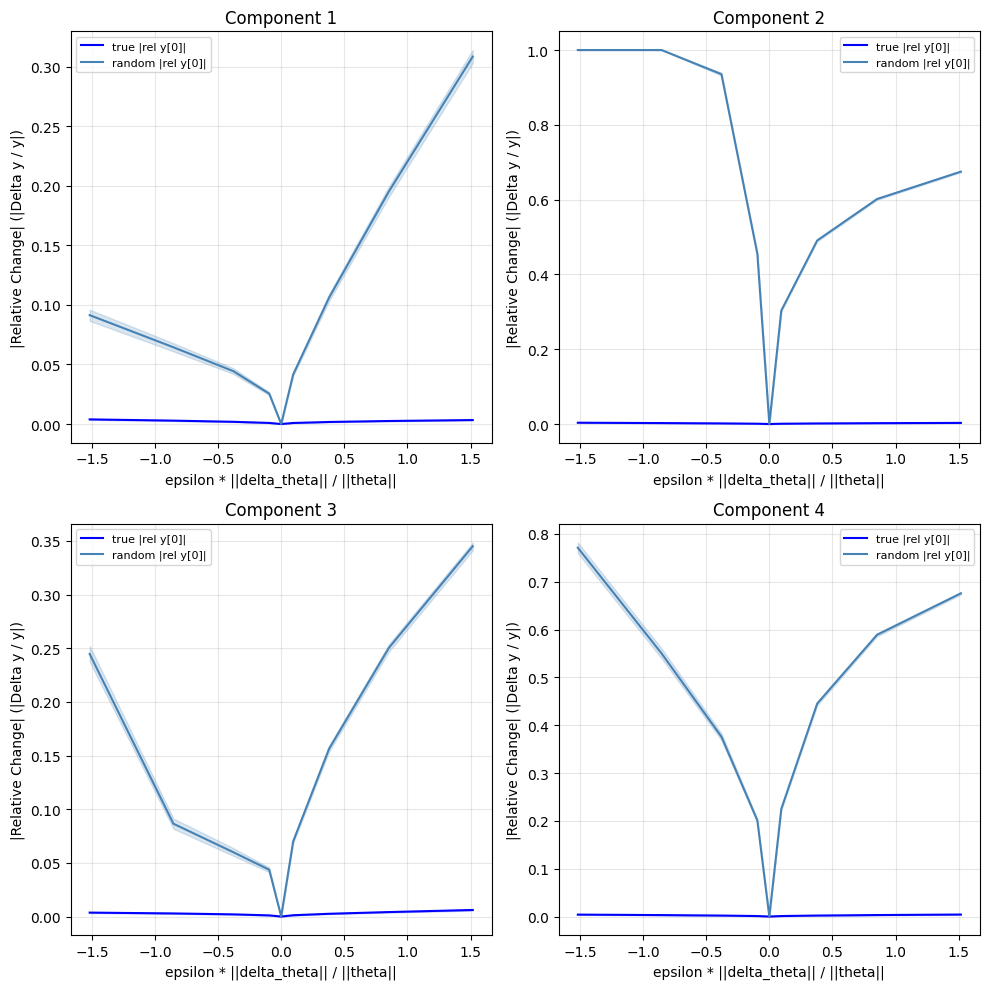

In [37]:
M = U1
e = np.arange(-2, 2+0.2, 0.5)
n_samples = 626  # Number of samples to process

theta_opt_subset = jnp.array(theta_opt[:n_samples])

key = jax.random.PRNGKey(0)

def _mitral_single(theta):
    return mitral_output(theta, x, m, n_r, n_b, n_g, n_y)

mitral_output_batch = jax.jit(jax.vmap(_mitral_single))

# Baseline y at epsilon = 0 (unperturbed theta)
_, _, _, y_baseline = mitral_output_batch(theta_opt_subset)
y_baseline = np.array(y_baseline)  # shape (n_samples, 2)

norm_theta_all = np.linalg.norm(theta_opt_subset, axis=1)
mean_norm_theta = np.mean(norm_theta_all)

n_components = M.shape[1]
n_rows = int(np.ceil(n_components / 2))
fig, ax = plt.subplots(n_rows, 2, figsize=(10, 5 * n_rows))
ax = np.atleast_1d(ax).flatten()
for j in range(n_components, len(ax)):
    ax[j].set_axis_off()

for k in range(n_components):
    true_dir = jnp.array(M[:, k])
    true_dir = true_dir / jnp.linalg.norm(true_dir)
    key, subkey = jax.random.split(key)
    random_dir = jax.random.normal(subkey, (M.shape[0],))
    random_dir = random_dir / jnp.linalg.norm(random_dir)

    for label, direction in [('true', true_dir), ('random', random_dir)]:
        y_save = []
        for i in range(len(e)):
            theta_step = theta_opt_subset + e[i] * direction
            _, _, _, y = mitral_output_batch(theta_step)
            y_save.append(np.array(y))
        y_array = np.array(y_save)  # (len(e), n_samples, 2)

        theta_ratio = np.array([e[i] * (np.linalg.norm(e[i] * direction) / mean_norm_theta) for i in range(len(e))])
        y0_baseline = y_baseline[:, 0]
        rel0 = np.where(np.abs(y0_baseline) > 1e-12,
                        (y_array[:, :, 0] - y0_baseline) / y0_baseline,
                        y_array[:, :, 0] - y0_baseline)
        abs_rel0 = np.abs(rel0)
        theta_ratio_expanded = np.repeat(theta_ratio, n_samples)

        c0 = 'blue' if label == 'true' else 'steelblue'
        sns.lineplot(x=theta_ratio_expanded, y=abs_rel0.ravel(), ax=ax[k], color=c0, label=f'{label} |rel y[0]|', errorbar=('ci', 95))

    ax[k].set_xlabel('epsilon * ||delta_theta|| / ||theta||')
    ax[k].set_ylabel('|Relative Change| (|Delta y / y|)')
    ax[k].set_title(f'Component {k+1}')
    ax[k].grid(True, alpha=0.3)
    ax[k].legend(fontsize=8)
plt.tight_layout()
plt.show()